# Manutenção Preditiva: previsão de falha em máquinas

Projeto de encerramento do Módulo 1. O objetivo é prever se uma máquina vai falhar (`falha_maquina` = 1) ou funcionar normalmente (`falha_maquina` = 0) a partir das leituras dos sensores, e comparar dois classificadores: **KNN** e **Árvore de Decisão**.

O código das funções está em `src/` (`data.py`, `graphs.py` e `training.py`). Este notebook chama essas funções fase por fase e explica as decisões que tomei em cada uma. As fases seguem o enunciado:

1. Análise Exploratória (EDA)
2. Limpeza e Tratamento de Dados
3. Feature Engineering
4. Divisão dos Dados (treino e teste)
5. Escalonamento (StandardScaler)
6. Ajuste de Parâmetros e Combate ao Overfitting
7. Avaliação e Veredito Final

In [1]:
import pandas as pd
from IPython.display import Image, display

from src.data import carregar_dados, explorar, limpar_dados
from src.graphs import COLUNAS, plotar_boxplots, plotar_grafico_barras, plotar_heatmap, plotar_histogramas
from src.training import (
    dividir_e_balancear,
    escalar_para_knn,
    potencia,
    treinar_arvore,
    treinar_knn,
    veredito,
)

pd.set_option('display.max_columns', None)


def mostrar(nome):
    """As funções de src/graphs.py salvam os gráficos em outputs/. Esta função mostra a imagem salva."""
    display(Image(f'outputs/{nome}.png'))

---
## Fase 1: Análise Exploratória (EDA)

Primeiro olho a base como ela veio, sem alterar nada: dimensões, tipos das colunas, resumo estatístico e valores nulos.

In [2]:
df = carregar_dados()
explorar(df)


 INSPECAO INICIAL DO DATASET
   udi id_produto tipo  temperatura_ar_k  temperatura_processo_k  \
0    1     M14860    M             298.1                   308.6   
1    2     L47181    L             298.2                   308.7   
2    3     L47182    L             298.1                   308.5   
3    4     L47183    L               NaN                     NaN   
4    5     L47184    L             298.2                   308.7   

   velocidade_rotacao_rpm  torque_nm  desgaste_ferramenta_min  falha_maquina  \
0                  1551.0       42.8                        0              0   
1                  1408.0       46.3                        3              0   
2                  1498.0       49.4                        5              0   
3                     NaN        NaN                        7              0   
4                  1408.0       40.0                        9              0   

   falha_twf  falha_hdf  falha_pwf  falha_osf  falha_rnf  
0          0         

**O que os números mostram**

- A base tem **10.000 linhas e 14 colunas**. `id_produto` e `tipo` são texto, e o resto é numérico.
- `temperatura_ar_k`, `temperatura_processo_k`, `velocidade_rotacao_rpm` e `torque_nm` têm **500 nulos cada** (5%), e pelo `describe()` os valores existentes parecem plausíveis para sensores.
- `udi` e `id_produto` são só identificadores. As colunas `falha_twf`, `falha_hdf`, `falha_pwf`, `falha_osf` e `falha_rnf` são os motivos da quebra, e as anotações da engenharia pedem para não usá-las como preditoras.

### Gráfico 1: balanceamento da variável alvo

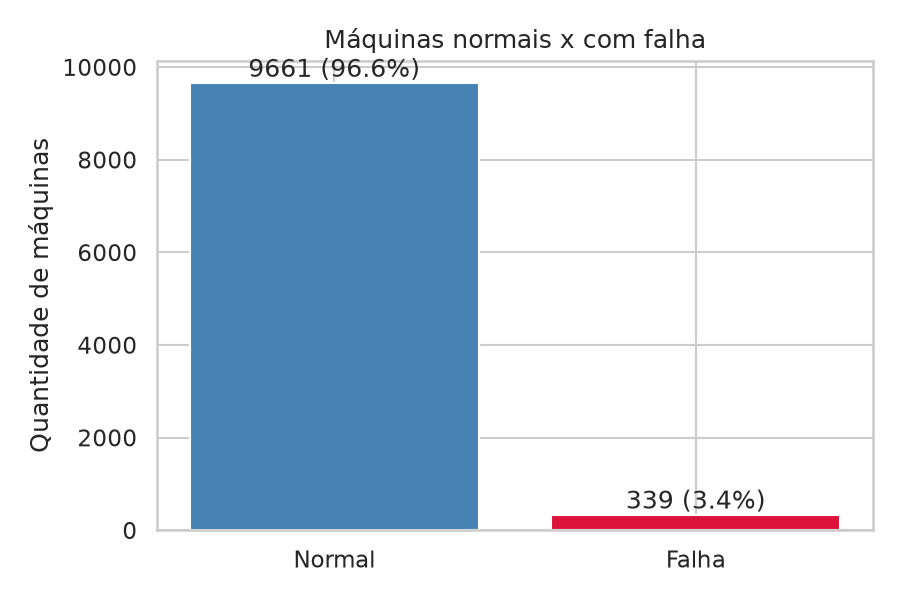

In [3]:
plotar_grafico_barras(df)
mostrar('grafico_barras')

Só **339 máquinas falharam (3,4%)** contra 9.661 normais (96,6%). A base é muito desbalanceada: um "modelo" que respondesse sempre "não vai falhar" acertaria 96,6% e não serviria para nada. Esse número vai ser a referência quando eu olhar as acurácias no final.

### Gráfico 2: distribuição de cada variável

As barras são empilhadas: a altura total é a quantidade de máquinas na faixa, e a parte vermelha é quantas dessas falharam.

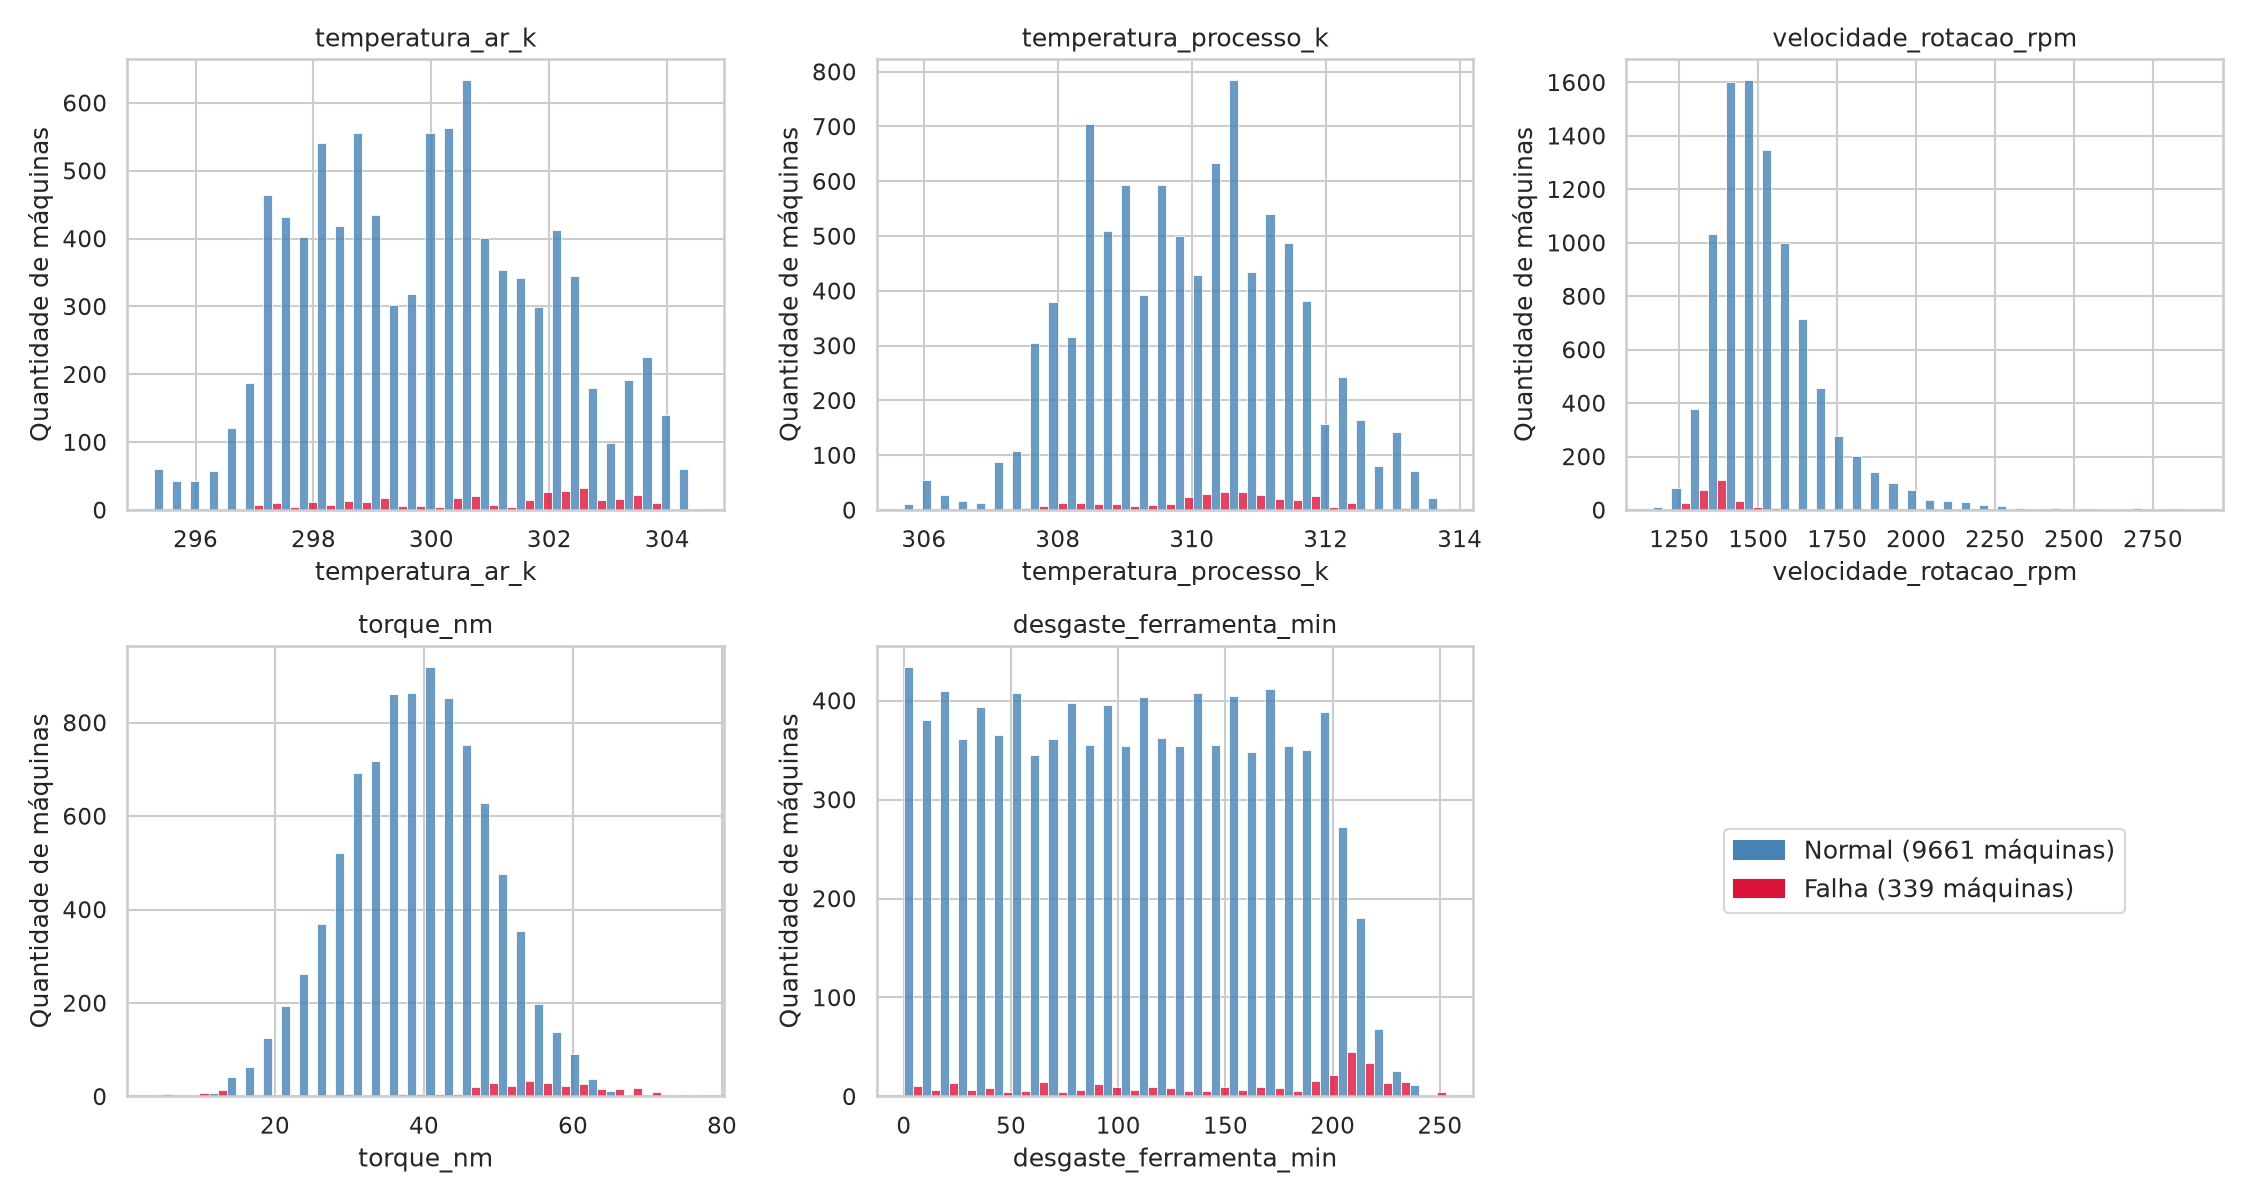

In [4]:
plotar_histogramas(df)
mostrar('histogramas')

### Gráfico 3: correlação de Pearson

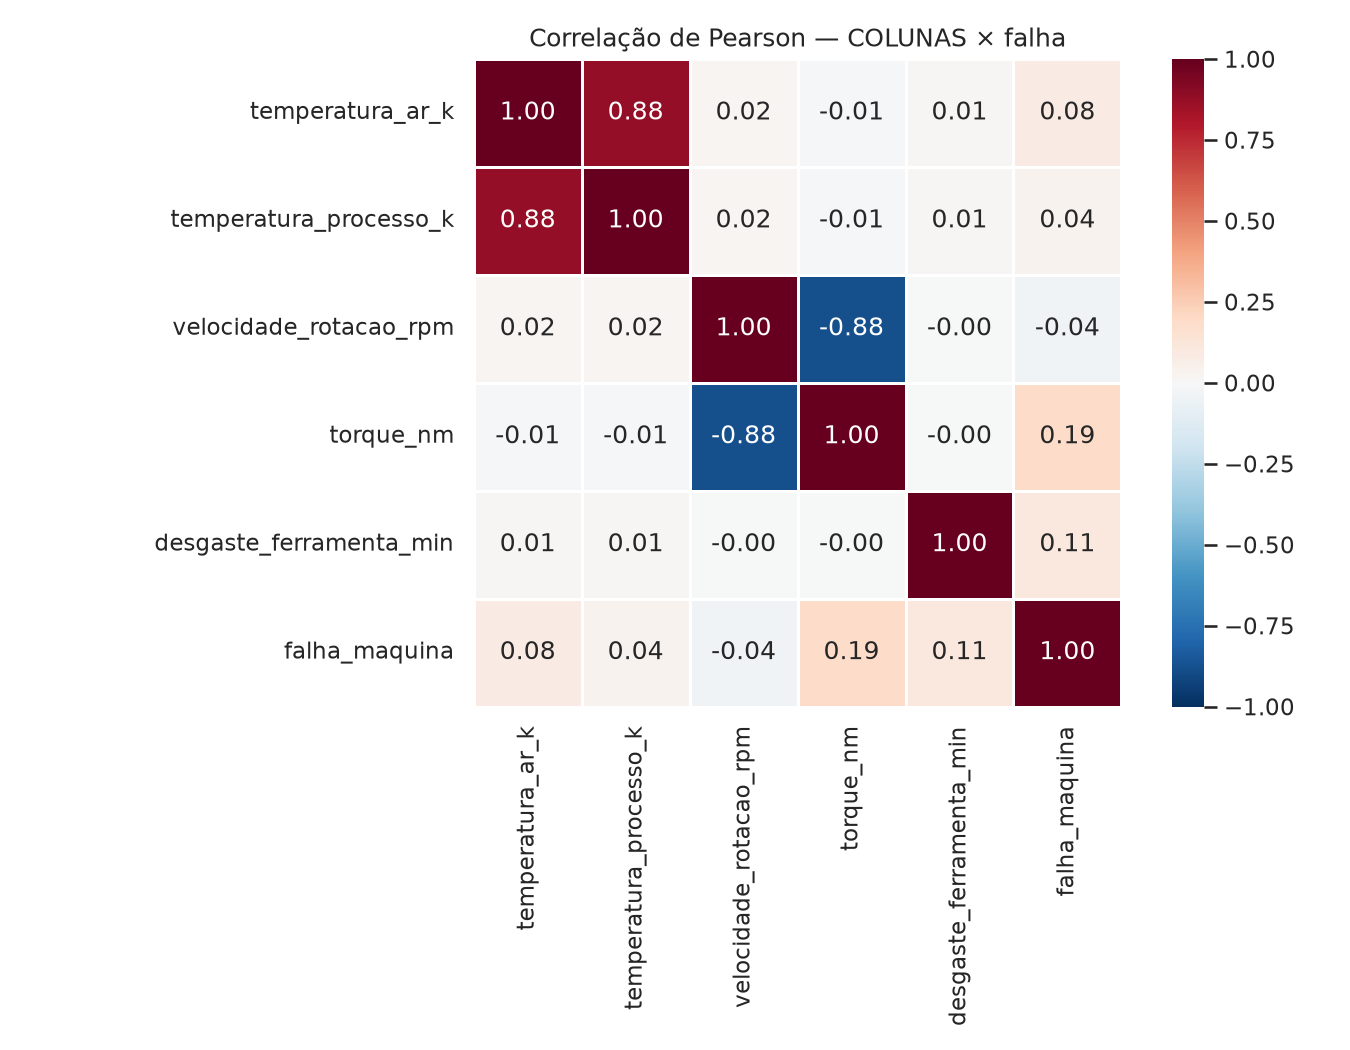

In [5]:
plotar_heatmap(df)
mostrar('heatmap_correlacao')

### Análise e estratégia de modelagem

**O que os gráficos mostram**

- **Desbalanceamento:** 339 falhas contra 9.661 máquinas normais.
- **Falhas aparecem em faixas de valores, não em linha reta.** Cerca de 123 das 339 falhas (36%) acontecem com desgaste de ferramenta acima de 200 min, enquanto as máquinas normais se distribuem de forma quase uniforme de 0 a 200. No torque, as falhas se concentram em valores altos (50 a 70 Nm) e há um grupo menor perto de 10 Nm, enquanto as normais ficam em torno de 40 Nm. Na rotação, as falhas ficam um pouco abaixo da média, em torno de 1.350 rpm.
- **A temperatura do processo quase não separa as classes:** as duas distribuições ficam praticamente uma sobre a outra.
- **Correlações com a falha são fracas:** `torque_nm` (0,19), `desgaste_ferramenta_min` (0,11), `temperatura_ar_k` (0,08), `temperatura_processo_k` (0,04) e `velocidade_rotacao_rpm` (-0,04). Isso não quer dizer que as variáveis não servem, porque o Pearson só enxerga relações lineares e o padrão aqui é por faixas.
- **Correlações fortes entre as próprias variáveis:** `temperatura_ar_k` e `temperatura_processo_k` (0,88) e `velocidade_rotacao_rpm` e `torque_nm` (-0,88, o que faz sentido, porque quando a rotação sobe o torque cai).
- **A rotação tem cauda longa à direita** (assimetria de aproximadamente 2): a média (1.539) é maior que a mediana (1.504).

**Como isso direciona a modelagem**

1. Por causa do desbalanceamento, vou dividir com `stratify=y` para manter a proporção de falhas no treino e no teste. A acurácia sozinha engana, e o 96,6% vai ser minha referência.
2. Como o padrão é por faixas, a **árvore de decisão** deve se dar bem, porque trabalha com cortes do tipo "desgaste > 200".
3. As variáveis estão em escalas bem diferentes (rotação na casa dos milhares, torque na casa das dezenas), e o KNN depende de distância, então ele precisa de **StandardScaler**. A colinearidade de 0,88 também significa que o KNN conta a temperatura "em dobro" na distância, o que a árvore não sofre.
4. A assimetria da rotação entra na decisão entre média e mediana na Fase 2.

---
## Fase 2: Limpeza e Tratamento de Dados (Data Prep)

A função `limpar_dados` aplica três etapas em ordem: remover espaços extras nos textos, **remover duplicados** e **imputar nulos**.

In [6]:
df_limpo, relatorio = limpar_dados(df)
relatorio


=== LIMPEZA DOS DADOS ===

[Espacos] Campos com espacos extras antes:
id_produto    0
tipo          0
dtype: int64
[Espacos] Campos com espacos extras depois:
id_produto    0
tipo          0
dtype: int64

[Duplicados] Registros antes: 10000
[Duplicados] Linhas duplicadas encontradas: 0
[Duplicados] Registros depois: 10000

[Nulos] Registros antes: 10000
[Nulos] Ausentes antes:
temperatura_ar_k          500
temperatura_processo_k    500
torque_nm                 500
velocidade_rotacao_rpm    500
dtype: int64
[Nulos] Média usada no preenchimento:
temperatura_ar_k           300.00
temperatura_processo_k     310.00
torque_nm                   39.97
velocidade_rotacao_rpm    1539.25
dtype: float64
[Nulos] Ausentes depois:
temperatura_ar_k          0
temperatura_processo_k    0
torque_nm                 0
velocidade_rotacao_rpm    0
dtype: int64
[Nulos] Registros depois: 10000


{'iniciais': 10000,
 'duplicados_removidos': 0,
 'nulos_preenchidos': {'temperatura_ar_k': 500,
  'temperatura_processo_k': 500,
  'torque_nm': 500,
  'velocidade_rotacao_rpm': 500},
 'finais': 10000}

**Duplicados:** não há nenhuma linha duplicada (0 de 10.000). A comparação usa a linha inteira. Se eu ignorasse `udi` e `id_produto`, o pandas apontaria 185 "duplicados", mas isso seria um erro: são máquinas com os 4 sensores vazios, que ficam iguais entre si. Por isso a remoção vem **antes** da imputação e usa todas as colunas.

**Nulos:** `temperatura_ar_k`, `temperatura_processo_k`, `torque_nm` e `velocidade_rotacao_rpm` têm 500 nulos cada, e são sempre as mesmas 500 máquinas (todos os sensores faltando ao mesmo tempo). Preenchi todos com a **média** da coluna, e o log mostra os valores usados (300,00; 310,00; 39,97 e 1.539,25).

**Por que a média:**

| Coluna | Média | Mediana | Assimetria |
|---|---|---|---|
| `temperatura_ar_k` | 300,0 | 300,1 | 0,11 |
| `temperatura_processo_k` | 310,0 | 310,1 | 0,02 |
| `torque_nm` | 39,97 | 40,1 | -0,01 |
| `velocidade_rotacao_rpm` | 1.539 | 1.504 | 1,99 |

Em três colunas a distribuição é simétrica e média e mediana são praticamente iguais, então a escolha não muda o resultado. Na rotação a distribuição é assimétrica (cauda de rotações altas) e, em teoria, a mediana seria mais robusta. Mesmo assim usei a média, por simplicidade e para tratar todas as colunas do mesmo jeito: a diferença entre as duas é de cerca de 35 rpm, que é pouco perto do desvio padrão da coluna (cerca de 180 rpm).

### Outliers

Os boxplots abaixo foram feitos com os dados já limpos.

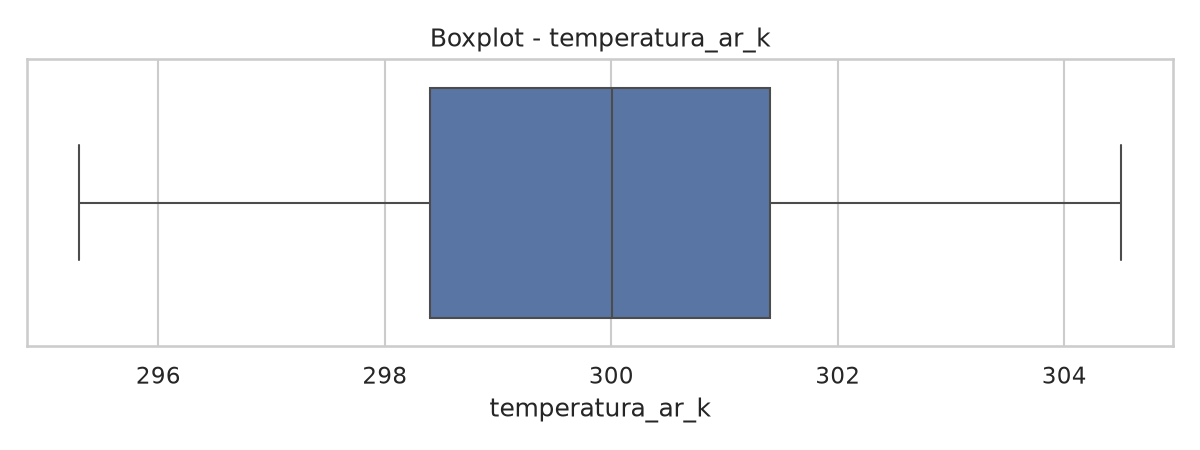

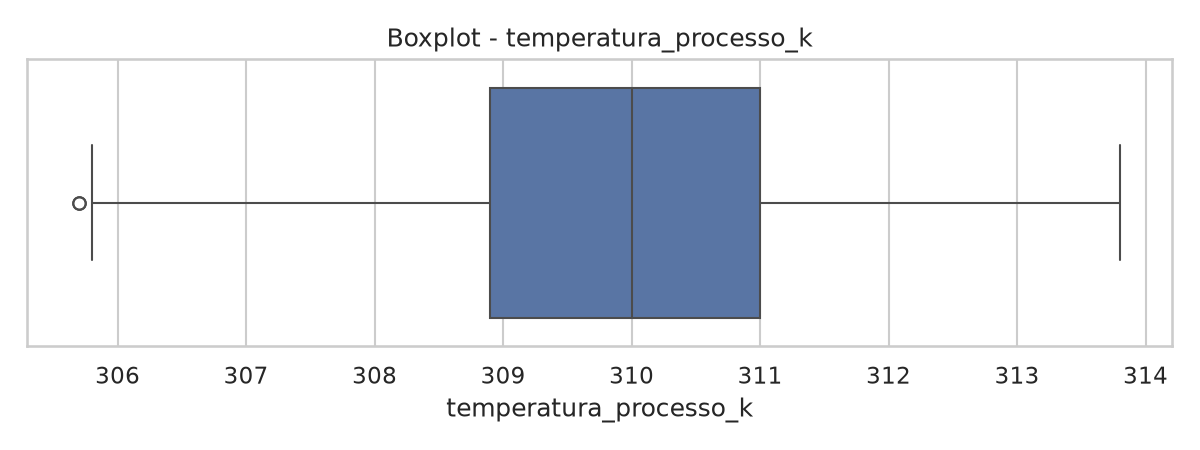

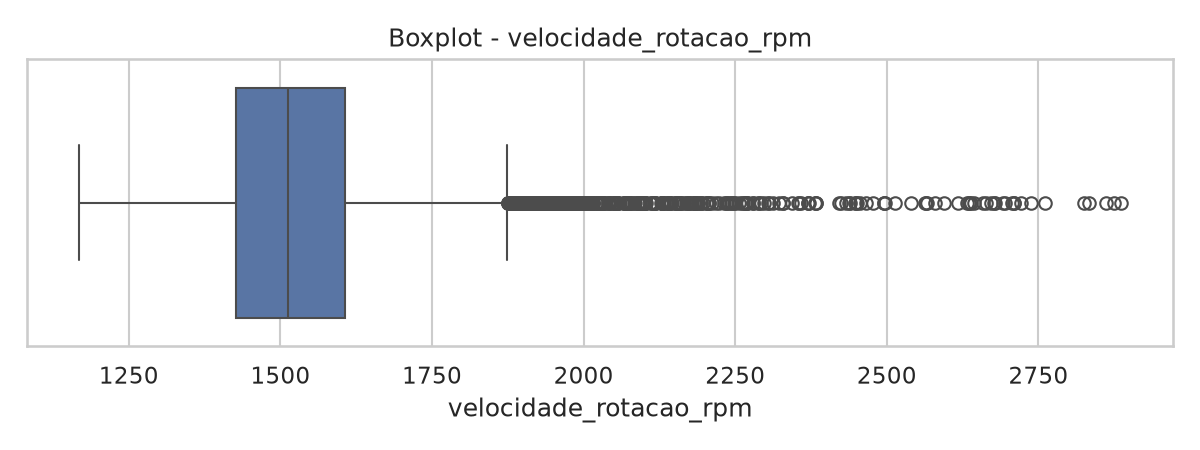

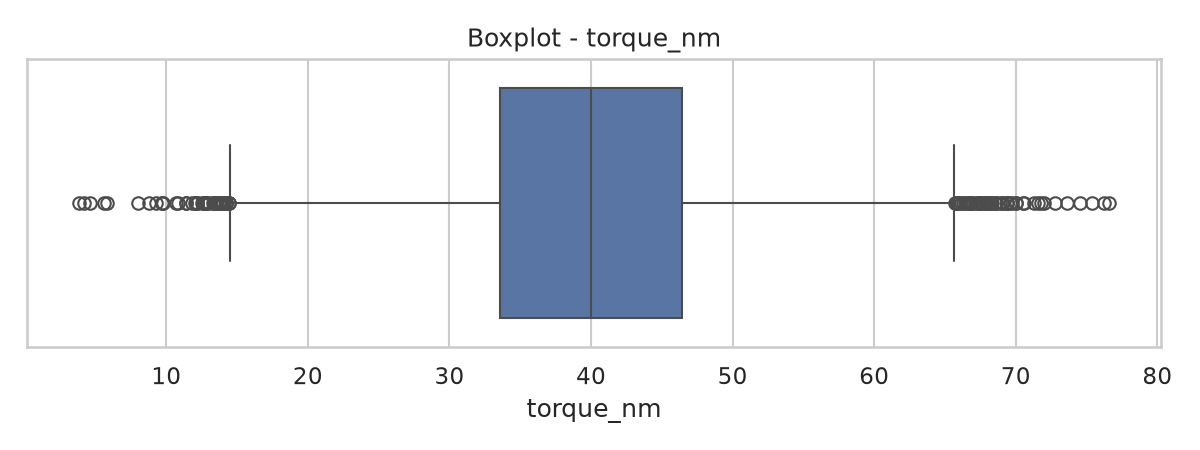

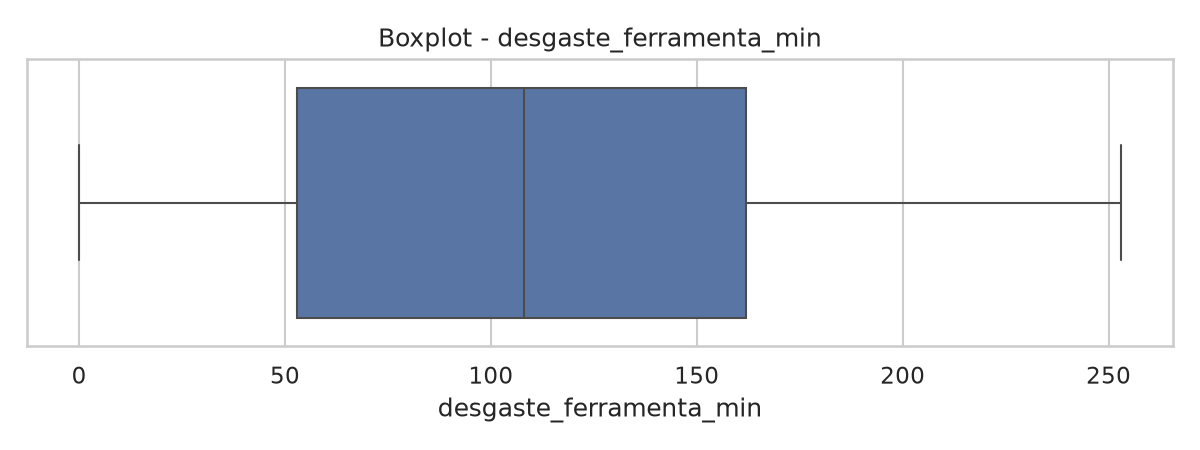

In [7]:
plotar_boxplots(df_limpo)
for coluna in COLUNAS:
    mostrar(f'boxplot_{coluna}')

**O que aparece nos boxplots** (pela regra do IQR, 1,5 vezes a amplitude):

- `velocidade_rotacao_rpm`: **465 outliers (4,7%)**, todos acima de aproximadamente 1.875 rpm. É a cauda longa que já tinha aparecido no histograma.
- `torque_nm`: **102 outliers (1,0%)**, fora de 14,4 a 65,6 Nm.
- `temperatura_processo_k`: apenas 2 outliers. `temperatura_ar_k` e `desgaste_ferramenta_min` não têm nenhum.

**Decisão: não removi os outliers.** O enunciado pede para identificá-los, e olhando mais de perto eles não são erros de medição, são leituras possíveis. Além disso, dos 102 outliers de torque, **72 são falhas (71%)**, o que equivale a cerca de 21% de todas as falhas da base. Removê-los jogaria fora justamente o sinal que o modelo precisa aprender. Na rotação, 7,3% dos outliers são falhas, contra 3,4% na base inteira. A árvore de decisão não é sensível a valores extremos, e o KNN fica protegido em parte pelo escalonamento.

---
## Fase 3: Feature Engineering

Criei a coluna `potencia = torque_nm * velocidade_rotacao_rpm`, a combinação sugerida pelo enunciado. Fisicamente, a potência mecânica de um motor é proporcional ao torque vezes a velocidade de rotação, então a coluna resume em um número o quanto a máquina está sendo exigida. A função só é chamada **depois** da imputação, porque se ela rodasse antes as 500 linhas com nulo gerariam `NaN` na nova coluna.

In [8]:
df_fe = potencia(df_limpo)
print('Nulos na potencia:', df_fe['potencia'].isnull().sum())
df_fe[['torque_nm', 'velocidade_rotacao_rpm', 'potencia']].describe()

Nulos na potencia: 0


,torque_nm,velocidade_rotacao_rpm,potencia
count,10000.000000,10000.000000,10000.000000
mean,39.974168,1539.245263,60031.655590
std,9.742337,175.708498,9956.975356
min,3.800000,1168.000000,10966.800000
25%,33.600000,1427.000000,53497.050000
50%,39.974168,1512.000000,60485.000000
75%,46.400000,1606.000000,66412.975000
max,76.600000,2886.000000,99980.400000


A coluna não tem nenhum nulo e os valores vão de cerca de 11.000 a 100.000, com média por volta de 60.000. A unidade é Nm x rpm, então não é watts, mas é proporcional à potência. A correlação dela com a falha é de aproximadamente 0,17, parecida com a do torque.

---
## Fase 4: Divisão dos Dados (treino e teste)

A função `dividir_e_balancear` faz, nesta ordem:

1. Separa `y` (`falha_maquina`) e `X` (o resto).
2. Transforma `tipo` (L, M, H) em colunas numéricas.
3. Divide em 80% treino e 20% teste com `stratify=y`.

Apesar do nome da função, **nesta versão não aplico nenhuma técnica de reamostragem** (explico mais abaixo).

In [9]:
X_treino, X_teste, y_treino, y_teste = dividir_e_balancear(df_fe)


Distribuição do alvo
falha_maquina
0    7729
1     271
Tamanho do treino 8000


In [10]:
print('Colunas do X:', list(X_treino.columns))
print()
print('Proporção de falhas no treino:')
print(y_treino.value_counts(normalize=True).round(4).to_string())
print()
print('Proporção de falhas no teste:')
print(y_teste.value_counts(normalize=True).round(4).to_string())
print()
print('Tamanho do treino:', len(X_treino), '| Tamanho do teste:', len(X_teste))

Colunas do X: ['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min', 'potencia', 'tipo_L', 'tipo_M']

Proporção de falhas no treino:
falha_maquina
0    0.9661
1    0.0339

Proporção de falhas no teste:
falha_maquina
0    0.966
1    0.034

Tamanho do treino: 8000 | Tamanho do teste: 2000


**Decisões:**

- **X e y separados.** O `y` é `falha_maquina`. Do X tirei `udi` e `id_produto` (identificadores, não são medidas de nada), o próprio alvo e as 5 colunas `falha_*`. Essas cinco só são preenchidas **depois** da quebra, então usá-las seria vazamento de dados: o modelo estaria lendo a resposta.
- **`tipo`** virou duas colunas (`tipo_L` e `tipo_M`) com `get_dummies(drop_first=True)`, porque o KNN só aceita números. A categoria H é a referência (as duas colunas zeradas). Fiz isso antes da divisão porque é só uma conversão de formato, sem aprender nada dos dados.
- **Divisão 80/20 com `stratify=y`:** 8.000 linhas de treino e 2.000 de teste. O treino ficou com 271 falhas (3,39%) e o teste com 68 (3,40%), então a proporção original foi mantida nos dois lados. Sem o `stratify`, a proporção de falhas no teste dependeria da sorte do sorteio, e com só 68 falhas isso mudaria bastante a acurácia.
- **Sem reamostragem:** os modelos são treinados com a base desbalanceada (7.729 máquinas normais para 271 com falha no treino) e testados na proporção real. É uma limitação: o modelo vê poucos exemplos de falha, então é mais fácil ele "aprender" a responder quase sempre "não falha". Isso pesa na leitura das acurácias no final.

---
## Fase 5: Escalonamento de Variáveis (StandardScaler)

O `StandardScaler` troca cada valor por "quantos desvios padrão ele está longe da média da coluna", deixando todas as colunas com média 0 e desvio 1. Aplico **só para o KNN**.

In [11]:
X_treino_esc, X_teste_esc = escalar_para_knn(X_treino, X_teste)

Média no treino escalado: {'temperatura_ar_k': 0.0, 'temperatura_processo_k': -0.0, 'velocidade_rotacao_rpm': 0.0, 'torque_nm': 0.0, 'desgaste_ferramenta_min': -0.0, 'potencia': 0.0}
Média no teste escalado:  {'temperatura_ar_k': -0.0014, 'temperatura_processo_k': 0.0005, 'velocidade_rotacao_rpm': -0.0136, 'torque_nm': -0.0114, 'desgaste_ferramenta_min': 0.0209, 'potencia': -0.0176}


**Por que o KNN precisa de escala:** ele decide pela distância entre máquinas, e a distância soma as diferenças de todas as colunas. As escalas são muito diferentes: o desvio padrão da rotação é de cerca de 180 rpm, o do torque de cerca de 10 Nm e o das temperaturas de 1,5 a 2 K. Sem escala, a rotação "engole" as outras colunas, e o KNN praticamente só olharia para ela. Também escalei `potencia`, que tem valores na casa das dezenas de milhares. As colunas `tipo_L` e `tipo_M` não foram escaladas, porque são categorias (0 ou 1).

**`fit_transform` no treino e `transform` no teste:** o scaler aprende a média e o desvio **só com o treino**, e o teste é transformado com esses mesmos valores. Se eu usasse `fit` no teste, ele usaria informação dos dados que deveriam ser desconhecidos. O log mostra isso: no treino a média das colunas escaladas é exatamente 0, e no teste fica perto de zero, mas não exatamente (desgaste em 0,02 e potência em -0,02, por exemplo). Essa pequena diferença é esperada e é a prova de que o teste não foi usado para calcular a escala.

**Por que a árvore de decisão fica sem escala:** ela não calcula distâncias. Em cada nó ela faz uma pergunta do tipo "o torque é maior que 55?", comparando uma coluna com um limite. Escalar uma coluna não muda a ordem dos valores, então os mesmos cortes continuam separando os mesmos grupos, e a árvore resultante é equivalente, com ou sem escala. Por isso `X_treino` e `X_teste` originais ficam intactos e são usados na árvore.

---
## Fase 6: Ajuste de Parâmetros e Combate ao Overfitting

Para cada modelo registro a acurácia no **treino** e no **teste**, e a diferença entre elas (`gap`). Treino muito acima do teste indica overfitting.

### KNN: K = 3, 5 e 7 (dados escalados)

In [12]:
tabela_knn = treinar_knn(X_treino_esc, X_teste_esc, y_treino, y_teste)


 KNN
 k  acc_treino  acc_teste    gap
 3      0.9832     0.9720 0.0112
 5      0.9792     0.9730 0.0062
 7      0.9769     0.9740 0.0029


### Árvore de Decisão: max_depth = 3, 5 e None (dados sem escala)

In [13]:
tabela_arvore = treinar_arvore(X_treino, X_teste, y_treino, y_teste)


 Árvore de decisão
max_depth  acc_treino  acc_teste    gap
        3      0.9759     0.9725 0.0034
        5      0.9810     0.9745 0.0065
     None      0.9990     0.9820 0.0170


### Onde houve overfitting

| Modelo | Treino | Teste | Gap |
|---|---|---|---|
| KNN, K=3 | 98,32% | 97,20% | 1,12 |
| KNN, K=5 | 97,92% | 97,30% | 0,62 |
| KNN, K=7 | 97,69% | 97,40% | 0,29 |
| Árvore, `max_depth=3` | 97,59% | 97,25% | 0,34 |
| Árvore, `max_depth=5` | 98,10% | 97,45% | 0,65 |
| Árvore, `max_depth=None` | 99,90% | 98,20% | 1,70 |

- **Árvore sem limite (`max_depth=None`):** é o overfitting mais claro. Ela chega a 99,90% no treino, quase decorando os dados, e cai para 98,20% no teste, o maior gap da tabela (1,70 ponto).
- **KNN com K=3:** tem um overfitting leve (gap de 1,12). Conforme o K aumenta, o gap diminui (0,29 em K=7), porque o modelo olha mais vizinhos e fica menos sensível a pontos isolados, e a acurácia de teste sobe junto (97,20% para 97,40%).
- **Árvores rasas (`max_depth` 3 e 5):** os gaps são pequenos (0,34 e 0,65). A de profundidade 3 é simples demais e acerta só 97,25% no teste.
- **Configuração mais estável:** no KNN, o **K=7** (gap de 0,29 e a melhor acurácia de teste entre os KNN). Na árvore, a **`max_depth=5`** é um bom equilíbrio (gap de 0,65 e 97,45% no teste). A de profundidade 3 tem gap menor, mas acerta menos.

As diferenças são pequenas: o teste tem 2.000 máquinas, então cada 0,1 ponto corresponde a 2 máquinas.

---
## Fase 7: Avaliação da Acurácia e Veredito Final

Para cada modelo escolho a configuração com a **maior acurácia no teste** e comparo.

In [14]:
veredito(tabela_knn, tabela_arvore)


 Veredito
  Melhor KNN:    K=7   acc_treino=0.9769 | acc_teste=0.9740
  Melhor Árvore: max_depth=None acc_treino=0.9990 | acc_teste=0.9820

  Modelo com maior acurácia no TESTE: Árvore (max_depth=None)


### Conclusão

| Modelo | Melhor configuração | Acurácia no teste |
|---|---|---|
| KNN | K = 7 | **97,40%** |
| Árvore de Decisão | `max_depth=None` | **98,20%** |

A **Árvore de Decisão** teve a maior acurácia no teste, **98,20% contra 97,40%** do KNN, uma diferença de 0,8 ponto percentual (cerca de 16 máquinas a mais acertadas nas 2.000 do teste). Ela também não precisou de escalonamento, e o resultado combina com o que a EDA indicou: as falhas aparecem em faixas de valores (desgaste acima de 200 min, torque alto), que são justamente cortes que a árvore faz bem.

**Recomendação:** adotar a árvore de decisão. Como a de `max_depth=None` sofre overfitting (99,90% no treino), uma opção mais segura para a empresa é a de `max_depth=5`, que é mais estável (98,10% no treino e 97,45% no teste) e fica no mesmo patamar do melhor KNN (97,40%) com um modelo bem mais simples.

**Ressalvas importantes:**

- **As acurácias ficaram entre 97,2% e 98,2%, só um pouco acima de 96,6%**, que é o que acertaria um modelo que respondesse sempre "não falha". O ganho é pequeno porque as falhas são raras (3,4%). A acurácia sozinha não mostra quantas das 68 falhas do teste cada modelo realmente encontra, e é provável que os modelos mais simples deixem passar a maioria delas.
- A diferença de 0,8 ponto vem de **um único** conjunto de teste, com apenas 68 falhas.

**O que eu melhoraria:**

- Avaliar também *recall*, precisão e matriz de confusão, que são mais adequados para dados desbalanceados.
- Usar validação cruzada em vez de uma única divisão treino/teste.
- Testar mais valores de K e de `max_depth` com uma busca sistemática (`GridSearchCV`).
- Testar uma técnica de reamostragem aplicada só no treino, para o modelo ver mais exemplos de falha.
- Tratar os nulos com mediana na rotação, e calcular as médias só com o treino para evitar qualquer vazamento.